In [4]:
# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split


In [10]:
df = pd.read_csv('data/study.csv', sep='\t')
df.head()

data = df.iloc[:, :-1].values # 처음부터 마지막 컬럼 직전까지의 데이터 (독립 변수 - 원인)
label = df.iloc[:, -1].values # 마지막 컬럼 데이터 (종속 변수 - 결과)
data[:2]

array([[0.5],
       [1.2]])

In [ ]:
# 훈련데이터, 테스트데이터 분류
train_data, test_data, train_label, test_label = train_test_split(
data, label, random_state=42)  

In [14]:
# 다항회귀 구현
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))

lr = LinearRegression() 
lr.fit(train_poly, train_label)
predict = lr.predict(test_poly)
print('예측 : ',predict)

예측 :  [-7.76591589 88.86660059 76.11829094  3.73626816 50.26134989]


In [15]:
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('학습데이터 예측 : ',score)
print('테스트데이터 예측 : ',score2)

학습데이터 예측 :  0.9851938548998579
테스트데이터 예측 :  0.8121250587972448


In [25]:
in_data = input('공부시간을 입력하세요.>> ')
in_data = float(in_data)
result = lr.predict([[in_data**2,in_data]])
print(f"공부시간에 따른 예측점수 : {result[0]:.2f} 점")

공부시간에 따른 예측점수 : -12.87 점


In [ ]:
# 구간별 직선을 그리기 위해 범위 정수배열 생성
point = np.arange(1,10)

In [19]:
# lr.coef_ : 다항회귀는 기울기가 2개 나옴, lr.intercept_ : y절편 
print(lr.coef_, lr.intercept_)


[-0.58329547 17.42329379] -16.331738919599772


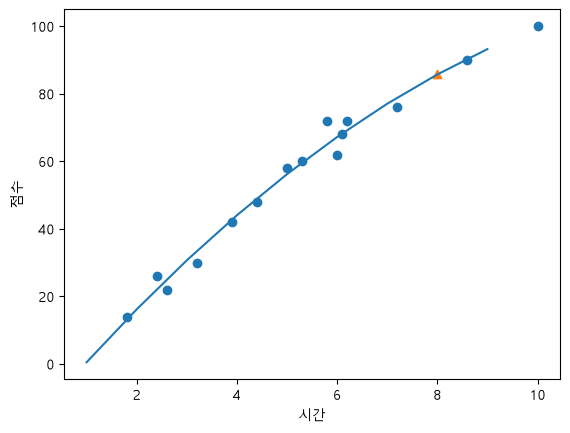

In [21]:
# 산점도 그래프
plt.scatter(train_data, train_label)
plt.scatter(8, 85.72, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('시간')
plt.ylabel('점수')
plt.show()